# **Icepack tutorial: meshes and functions**

## **Meshes**  
Create mesh using firedrake:

In [38]:
import firedrake
# Mesh dimensions
nx, ny = (16, 16)
# Generate mesh
mesh = firedrake.UnitSquareMesh(nx, ny)

Mesh plots, shown with a different colour for each segment of the boundary. Legend shows how the colours correspond to the numeric IDs of each boundary segment (can be useful when applying different boundary conditions to different segments):

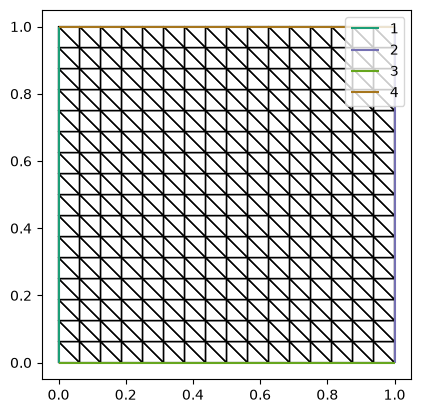

In [39]:
import matplotlib.pyplot as plt
# Generate plot
fig, axes = plt.subplots()
axes.set_aspect("equal")
firedrake.triplot(mesh, axes=axes)
axes.legend(loc="upper right")

## **Functions**  
Make scalar and vector fields defined on this mesh by interpolating the values of an algebraic expression to some space of functions.  
1) Construct function space *Q*. Element family - in most cases - consists of continuous piecewise-polynomial functions in each triangle, CG (continuous Galerkin). Also decide polynomial degree.
2) Make an expression for the function and interpolate it to the function space *Q*. The function firedrake.SpatialCoordinate returns *x, y* for the coordinates of each point of the mesh. Can then use *x, y* to define expressions for the function we'd like to analyse.
3) Create function *q* that lives in *Q* by calling firedrake.Function.
4) Invoke the method *.interpolate* of the function *q*. This takes in an expression and fills the values of *q* with that expression, evaluated at all its degrees of freedom. 

In [40]:
# Function space Q
Q = firedrake.FunctionSpace(mesh, family="CG", degree=2)

# Coordinates for each point on the mesh
x, y = firedrake.SpatialCoordinate(mesh)
# Define constants
a = firedrake.Constant(0.5)
b = firedrake.Constant(10.0)
# Equation 
expr = (a - x)**2 + b*(y - x**2)**2
# Interpolate equation into function space
q = firedrake.Function(Q)
q.interpolate(expr)

Coefficient(WithGeometry(FunctionSpace(<firedrake.mesh.MeshTopology object at 0x73889d8e7260>, FiniteElement('Lagrange', triangle, 2), name=None), Mesh(VectorElement(FiniteElement('Lagrange', triangle, 1), dim=2), 93)), 188)

Can also do *q = firedrake.Function(Q).interpolate(expr)*  

Now we can make a contour plot of the function we created. The functions *tricontour*, *tricontourf*, *tripcolor* and *quiver* are equivalents of matplotlib (check out their code for explanations)

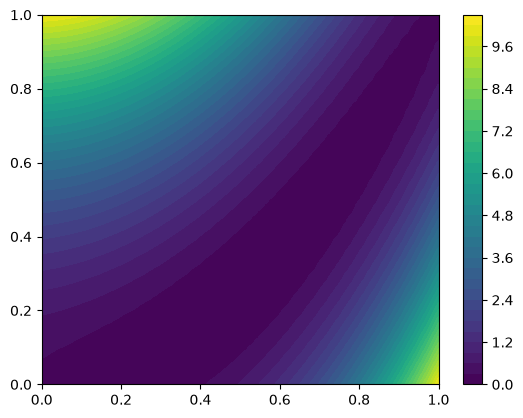

In [41]:
fig, axes = plt.subplots()
contours = firedrake.tricontourf(q, 36, axes=axes)
fig.colorbar(contours)

Now we can make vector fields.  
1) Put the expression we want inside the function *as_vector* in order to specify that we want a field with more than one component (also *as_tensor* function if you want a matrix field).
2) Interpolate into a vector function space.

In [42]:
from firedrake import as_vector
# Put expression in vector function
expr = as_vector(
    (
        2 * (a - x) + 4 * b * x * (y - x**2),
        -2 * b * (y - x**2),
    )
)

V = firedrake.VectorFunctionSpace(mesh, family="CG", degree=2)
# Interpolate 
v = firedrake.Function(V).interpolate(expr)

Here, we plot streamlines of the vector field coloured according to vector magnitude. This method is expensive, especially if the resolution or spacing of the streamlines is too small, but produces nice graphics.

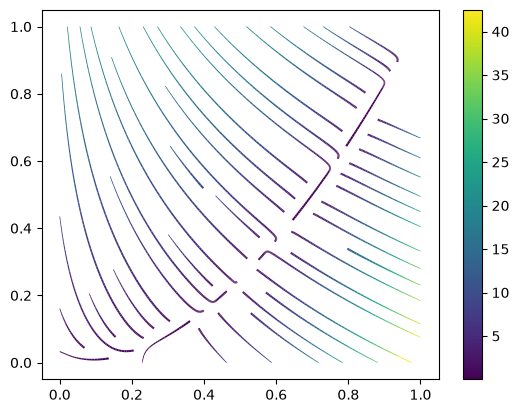

In [43]:
fig, axes = plt.subplots()
opts = {"resolution": 1 / 32, "seed": 1}
streamlines = firedrake.streamplot(v, axes=axes, **opts)
fig.colorbar(streamlines);

## **Post-processing**  
There is more to analysing the results of simulations. For starters, you can evaluate scalar or vector fields at points in the domain:


In [44]:
z = (a, a**2)
print(q(z))
print(v(z))

-2.5559595073374278e-18
[-1.32315738e-15  1.25002964e-15]


Firedrake also provide a set of operations for evaluating integral expressions of scalar and vector fields.  
  
Like the function *SpatialCoordinate* gives *x, y* for mesh coordinates, Firedrake provides *dx* which represents the differential area element. To define an integral, multiply an expression by *dx*. This gives back a symbolic object representing a recipe fo computing an integral; we haven't yet evaluated it to get a real number. The function *firedrake.assemble* actually evaluates this symbolic expression to give us a number.  

This is similar to *interpolate*; expressions defining fields need interpolated, expressions defining integrals need assembled.  

In [45]:
from firedrake import inner, dx, assemble
print(assemble(x * y * dx))
print(assemble(q * dx))
print(assemble(inner(v, v) * dx))

0.25000000000000006
2.0833346048990866
172.01609669791287


Can also evaluate integrals over the boundary of the mesh rather than the interior - use *ds* instead.

In [46]:
from firedrake import ds
print(assemble(q * ds))

14.666669209798181


We may need to specify the boundary we're integrating over. The first mesh plot shows the boundaries are numbered. We can specify which boundary segment by passing the corresponding numeric IDs to *ds*.

In [47]:
print(assemble(q * ds(2)))

ids = (1, 2)
print(assemble(q * ds(ids)))

3.583333333333333
7.166666666666664


Finally, a common operation is to evaluate the flux of a vector field *v* across the boundary of a domain. We'll need a symbolic representation of the outward-pointing normal; this comes from the function *firedrake.FacetNormal*.

In [48]:
n = firedrake.FacetNormal(mesh)
print(assemble(inner(v, n) * ds))

-42.00000000000001


## **Common useful functions**  
Here, we synthesise some field - an ice thickness or bed elevation, for example - with a shape that mimics a feature of a real physical system. There are a few useful functions for doing this.  
First, the hyperbolic tangent function: *tanh(z) = sinh(z)/cosh(z)* goes from -1 as z -> -∞ to +1 as z -> +∞.  
Firedrake also defines symbolic expressions involving transcendental functions like the exponential, logarithm, sine, and cosine.

In [59]:
from firedrake import exp

def sinh(z):
    return (exp(z) - exp(-z)) / 2

def cosh(z):
    return (exp(z) + exp(-z)) / 2

def tanh(z):
    return sinh(z) / cosh(z)

By shifting and rescaling the output tanh function or its argument, we can create ramping functions that go from one value to another over some length scale that we choose. Here we create a ramp function that goes from a value *a* to value *b* over a distance δ = 1/8 across the diagonal line through the center of the domain.

In [60]:
a = firedrake.Constant(-2)
b = firedrake.Constant(+3)
x_0 = firedrake.Constant(1/2)
y_0 = firedrake.Constant(1/2)
δ = firedrake.Constant(1/8)

w = (x - x_0) / δ + (y - y_0) / δ
expr = a + (b - a) * (tanh(w) + 1) / 2
ramp = firedrake.Function(Q).interpolate(expr)

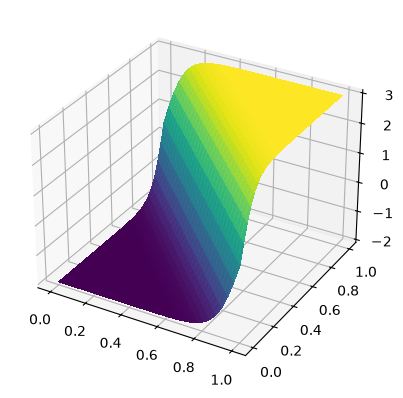

In [61]:
from mpl_toolkits import mplot3d
fig = plt.figure()
axes = fig.add_subplot(projection='3d')
firedrake.trisurf(ramp, axes=axes);

We can also create a ramping function around a circle of radius 1/4 in the middle of the domain:

In [62]:
from firedrake import sqrt
r = sqrt((x - x_0)**2 + (y - y_0)**2)
R = firedrake.Constant(1/4)
ϵ = firedrake.Constant(1/16)
expr = tanh((R - r) / ϵ)
ramp = firedrake.Function(Q).interpolate(expr)

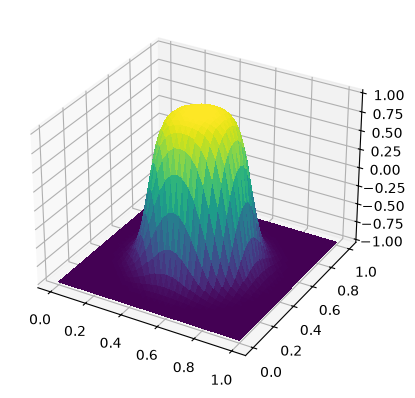

In [63]:
fig = plt.figure()
axes = fig.add_subplot(projection="3d")
firedrake.trisurf(ramp, axes=axes);

Another useful shaping function is the hyperbolic secant: *sech(z) = 1/cosh(z)*, good for making bumps:

In [64]:
def sech(z):
    return 1 / cosh(z)

expr = sech(r / δ)
bump = firedrake.Function(Q).interpolate(expr)

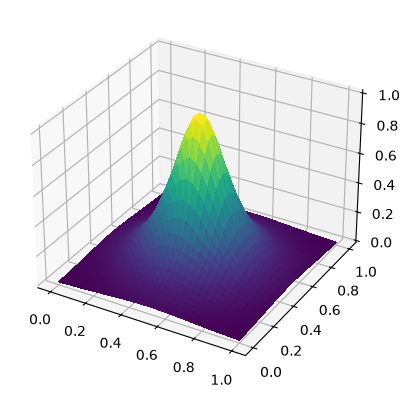

In [65]:
fig = plt.figure()
axes = fig.add_subplot(projection="3d")
firedrake.trisurf(bump, axes=axes)

It is possible to use other bump functions like *e<sup>-z<sup>2</sup></sup>, sech<sup>2</sup>, etc. Here, we create a ridge at a circle of radius 1/4 about the center of the domain.

In [66]:
expr = sech((r - R) / δ)
ridge = firedrake.Function(Q).interpolate(expr)

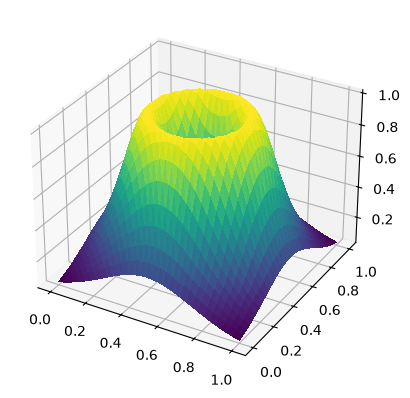

In [67]:
fig = plt.figure()
axes = fig.add_subplot(projection="3d")
firedrake.trisurf(ridge, axes=axes);

To synthesise fields like bed topography, these functions can be used.